# Plot the time series of each simulation 

In [10]:
import numpy as np
import os
import astropy.units as u
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable

import h5py
import json

from field_config import field_labels, field_lims, field_scales

In [11]:
bowshock_config_dict = json.load(open("../config/bowshock_config.json"))
bowshock_config = bowshock_config_dict["config"]
shock_labels = bowshock_config_dict["shock_labels"]

fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/crshock"

### Plotting shock parameter in each row, model in each column

The angular dependence is plotted using a cmap color scheme following the bow shock colors

In [12]:
params = ["encr", "shma", "geff", "alpha_inj"]
bs_names = list(bowshock_config.keys())
bs_names.remove("ISM-v30-MHD")
bs_names.remove("ISM-v60")
shock_type = "outer"

# create a custom qualitative cmap based on the average quantity of the theta range
theta_ranges_plot = np.arange(0, 210, 30)
theta_cmap = cm.viridis
theta_norm = mcolors.Normalize(vmin=0, vmax=180, clip=False)

theta_ranges_color = [theta_cmap(theta_norm(th)) for th in theta_ranges_plot]

theta_ranges_cmap = mcolors.LinearSegmentedColormap.from_list('theta_cmap', theta_ranges_color, len(theta_ranges_color))
theta_ranges_norm = mcolors.BoundaryNorm(theta_ranges_plot, theta_ranges_cmap.N)

In [13]:
param_textpos = {"encr": 1e-11, "shma": 25, "crac": 0.15, "geff": 1.65, "alpha_inj":4.0}

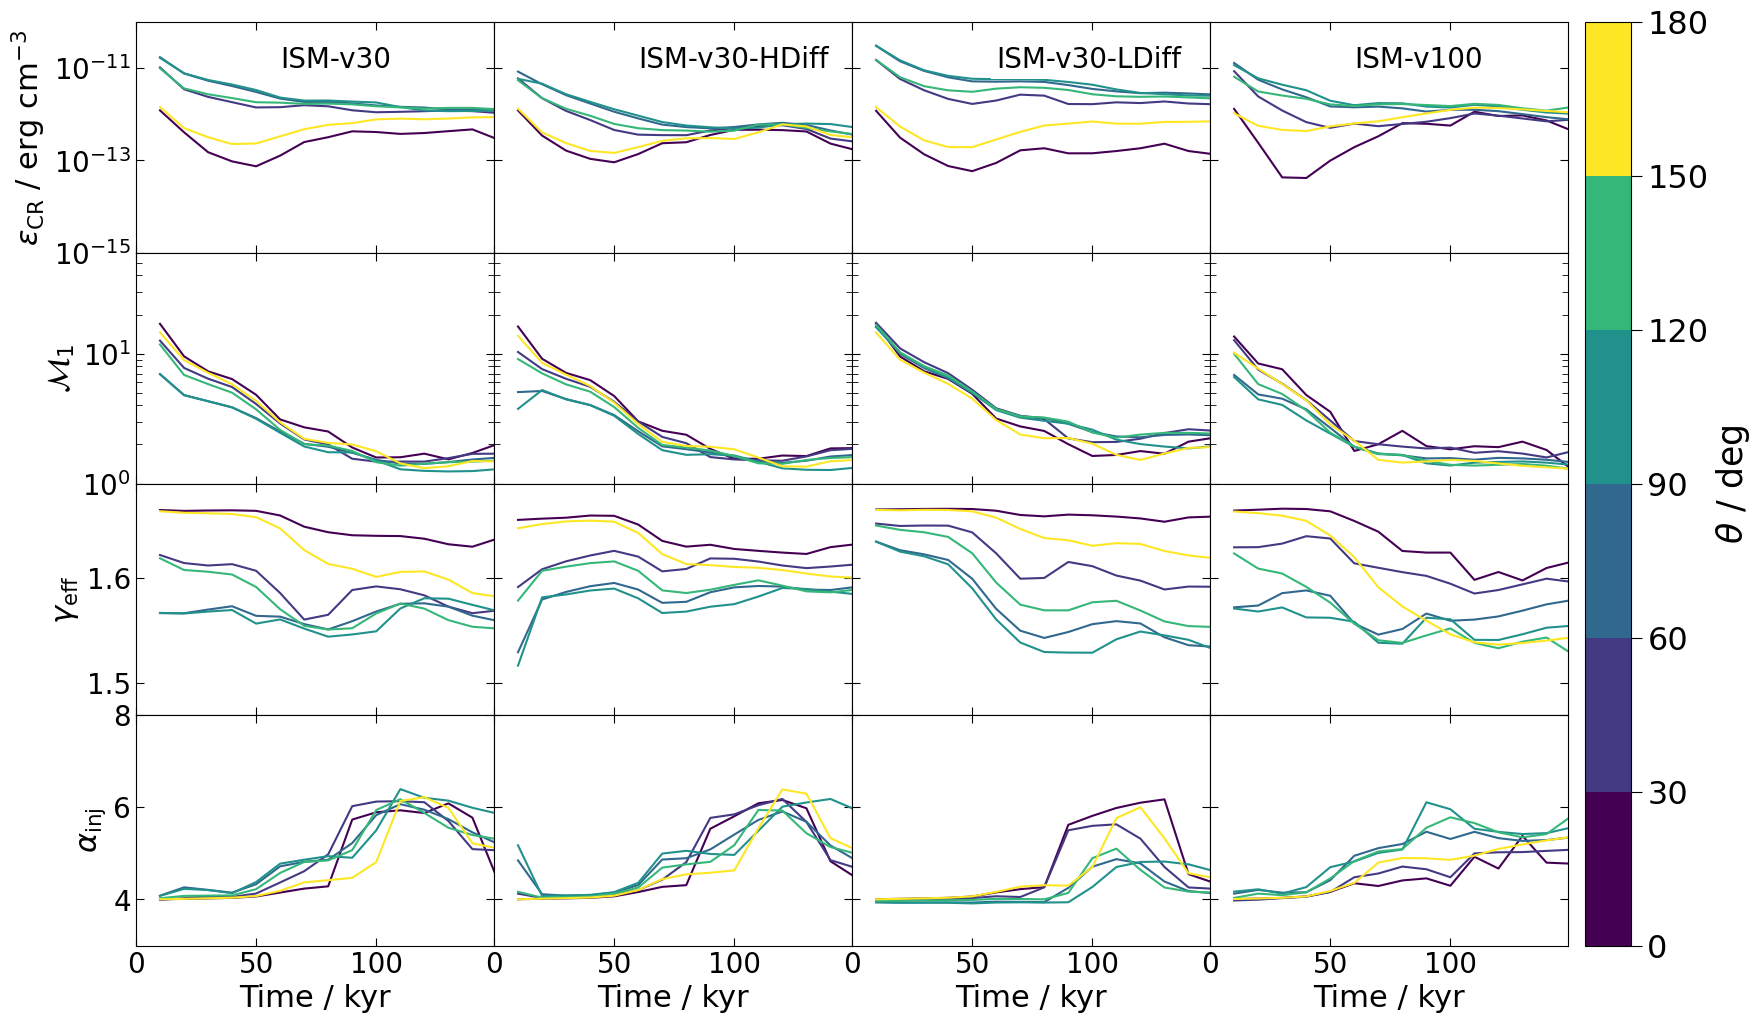

In [14]:
fig = plt.figure(figsize=(22, 12))
gs = fig.add_gridspec(len(params), len(bs_names), hspace=0, wspace=0)
axs = gs.subplots(sharex=True, sharey=False)

for ip, p in enumerate(params):
    with h5py.File(f"../data/polar_time_series_{shock_type}.h5", "r") as f:
        
        for ibs, bs_name in enumerate(bs_names):
            # if bs_name in set(["ISM-v60"]):
            #     continue
            times = (f[bs_name]["times"][()] * u.s).to(u.kyr)
            theta_range_sims = f[bs_name]["theta_ranges"][()]
            theta_minval_sims = [th_sim[0] for th_sim in theta_range_sims]
            theta_maxval_sims = [th_sim[1] for th_sim in theta_range_sims]

            param_arr = f[bs_name][p][()]

            if p == "vel":
                param_arr *= 1e-5
            if p == "mag":
                param_arr *= 1e6

            for itr, theta_maxval in enumerate(theta_ranges_plot[1:]):
                theta_minval_idx = np.digitize(theta_ranges_plot[itr], theta_minval_sims, right=True)
                theta_maxval_idx = np.digitize(theta_maxval, theta_maxval_sims, right=True)

                theta_mean = 0.5 * (theta_ranges_plot[itr] + theta_maxval)
                pl = axs[ip, ibs].plot(
                    times,
                    np.mean(param_arr[:, theta_minval_idx:theta_maxval_idx+1], axis=-1),
                    color=theta_ranges_cmap(theta_ranges_norm(theta_mean)),
                )

            # labels
            axs[ip, ibs].set_xlabel("Time / kyr", fontsize=22)
            if ibs == 0:
                axs[ip, ibs].set_ylabel(field_labels[p], fontsize=22)

            # limits
            axs[ip, ibs].set_xlim([0, 149])
            axs[ip, ibs].set_ylim(field_lims[p])

            # scales
            axs[ip, ibs].set_yscale(field_scales[p])

            # ticks
            axs[ip, ibs].tick_params(
                axis="x", direction="in", which="major", size=6, labelsize=20, top=True
            )
            axs[ip, ibs].tick_params(
                axis="x", direction="in", which="minor", size=4, labelsize=16, top=True
            )
            axs[ip, ibs].tick_params(
                axis="y",
                direction="in",
                which="major",
                size=6,
                labelsize=20,
                right=True
            )
            axs[ip, ibs].tick_params(
                axis="y",
                direction="in",
                which="minor",
                size=4,
                labelsize=16,
                right=True
            )

            if ibs != 0:
                axs[ip, ibs].yaxis.set_ticklabels([])

            if ip == 0:
                axs[ip, ibs].annotate(
                    f"{bs_name}",
                    xy=(60, param_textpos[p]),
                    fontsize=20,
                    bbox=dict(facecolor="white", edgecolor="none"),
                )

# colorbar
sm = cm.ScalarMappable(cmap=theta_ranges_cmap, norm=theta_ranges_norm)
cbar = fig.colorbar(sm, ax=axs.ravel().tolist(), pad=0.01)
cbar.ax.set_ylabel(r"$\theta$ / deg", fontsize=25)
cbar.ax.tick_params(axis="both", which="major", size=8, labelsize=23)
cbar.ax.tick_params(axis="both", which="minor", size=6, labelsize=23)

fig.savefig(
    os.path.join(fig_dir, f"timeseries_{shock_type}.pdf"),
    dpi=200,
    bbox_inches="tight",
)
